# Módulo 16: Aplicación de la analítica — Solución

> Solución de referencia de la guía [m16-aplicacion-de-analitica-guia.ipynb](m16-aplicacion-de-analitica-guia.ipynb). No es una tarea entregada del programa.

Lección del módulo: [m16-aplicacion-de-analitica-leccion.md](m16-aplicacion-de-analitica-leccion.md)

## Contexto

**Resonar** es una startup de pódcast en español con unas 40 personas. Produce y licencia programas de crimen, negocios y tecnología, ciencia, humor, deportes y cultura, y se financia con una suscripción sin anuncios y con publicidad en el plan gratuito. Acaba de cerrar una ronda de inversión y los inversores le piden dos cosas: **que los usuarios nuevos se queden** y **que las decisiones de producto se tomen con datos**.

Hasta ahora, un único analista preparaba informes a mano. La dirección quiere formar un equipo de ciencia de datos pequeño y te pide una propuesta.

Como primera prueba, el equipo de producto lanzó un experimento con la función **"Cola automática"**: al terminar un episodio empieza el siguiente que el sistema recomienda, en lugar de detenerse. Los 3 000 usuarios que se registraron entre el 2 y el 8 de marzo de 2026 se asignaron al azar, mitad y mitad, al grupo **A** (control, sin la función) y al grupo **B** (con la función), y se registró su escucha hasta el 5 de abril.

## Datos

La celda inicial genera el DataFrame `eventos`, con una fila por sesión de escucha de un episodio:

| Columna | Descripción |
| --- | --- |
| `usuario_id` | Identificador del usuario |
| `contenido` | Nombre del programa escuchado |
| `categoria` | Categoría del programa |
| `fecha` | Fecha de la sesión |
| `minutos` | Minutos escuchados en la sesión |
| `grupo` | Grupo del experimento: `A` (control) o `B` (con cola automática) |

Cada usuario escuchó al menos un episodio el día en que se registró, así que **la fecha de su primer evento es su fecha de alta** y los 3 000 usuarios aparecen en la tabla. El DataFrame `catalogo` lista los 15 programas con su categoría. Los datos son sintéticos y se generan con una semilla fija, así que siempre obtendrás los mismos valores.

## Instrucciones

1. **Aplicaciones priorizadas:** cinco aplicaciones valoradas por impacto y viabilidad, y las tres primeras justificadas.
2. **Composición del equipo:** 4 a 6 roles con responsabilidades, áreas con las que trabajan y orden de contratación.
3. **Cómo medir el éxito:** métrica principal, métricas de éxito y de control por aplicación, atribución y éxito del equipo.
4. **Métricas de engagement:** DAU, minutos por usuario activo, patrón semanal y programas más escuchados.
5. **Recomendación por coocurrencia:** matriz usuario × programa, coocurrencias, confianza, lift y función `recomendar`.
6. **Prueba A/B de la cola automática:** retención en la semana 4 por grupo, prueba z de proporciones, tamaño del efecto y métrica de control.

### Carga de los datos

La celda siguiente es idéntica a la de la guía: genera los mismos eventos con la semilla 42.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

catalogo = pd.DataFrame({
    "contenido": ["Crimen sin Resolver", "Expedientes del Sur", "Casos Fríos",
                  "Startups al Día", "Código Abierto", "Finanzas en Corto",
                  "Ciencia de Bolsillo", "El Universo en 20 Minutos", "Mente Curiosa",
                  "Risas de Sobremesa", "Comedia sin Guion",
                  "La Jugada", "Tiempo Extra",
                  "Historias de Abuela", "Viajes Lentos"],
    "categoria": ["Crimen"] * 3 + ["Negocios y tecnología"] * 3 + ["Ciencia"] * 3
                 + ["Humor"] * 2 + ["Deportes"] * 2 + ["Cultura"] * 2,
})
categorias = catalogo["categoria"].unique()
prob_categoria = [0.25, 0.22, 0.18, 0.15, 0.12, 0.08]
todos = catalogo["contenido"].to_numpy()

n_usuarios = 3000
inicio, fin = pd.Timestamp("2026-03-02"), pd.Timestamp("2026-04-05")  # inicio es lunes
grupos = rng.permutation(np.repeat(["A", "B"], n_usuarios // 2))
dia_alta = rng.integers(0, 7, n_usuarios)  # días desde el 2 de marzo

filas = []
for uid in range(n_usuarios):
    # Programas favoritos: dos de una categoría preferida, más algunos hábitos cruzados
    cat = rng.choice(categorias, p=prob_categoria)
    propios = catalogo.loc[catalogo["categoria"] == cat, "contenido"].to_numpy()
    favoritos = list(rng.choice(propios, size=2, replace=False))
    if "Startups al Día" in favoritos and "Código Abierto" not in favoritos and rng.random() < 0.7:
        favoritos.append("Código Abierto")
    if "Crimen sin Resolver" in favoritos and rng.random() < 0.5:
        favoritos.append("Historias de Abuela")

    actividad = rng.beta(2, 4)
    decaimiento = 0.045 if grupos[uid] == "A" else 0.040
    for d in range((fin - inicio).days - dia_alta[uid] + 1):
        dia = dia_alta[uid] + d
        fin_de_semana = dia % 7 >= 5
        p = actividad * np.exp(-decaimiento * d) * (0.6 if fin_de_semana else 1.0)
        if d == 0 or rng.random() < p:
            for _ in range(1 + rng.poisson(0.5)):
                prog = rng.choice(favoritos) if rng.random() < 0.8 else rng.choice(todos)
                filas.append((uid + 1, prog, dia, round(float(rng.gamma(2.5, 9)), 1), grupos[uid]))

eventos = pd.DataFrame(filas, columns=["usuario_id", "contenido", "dia", "minutos", "grupo"])
eventos["fecha"] = inicio + pd.to_timedelta(eventos["dia"], unit="D")
eventos = eventos.merge(catalogo, on="contenido")
eventos = eventos[["usuario_id", "contenido", "categoria", "fecha", "minutos", "grupo"]]
eventos = eventos.sort_values(["fecha", "usuario_id"], ignore_index=True)
eventos.head()

,usuario_id,contenido,categoria,fecha,minutos,grupo
0,4,Historias de Abuela,Cultura,2026-03-02,18.8,A
1,4,Ciencia de Bolsillo,Ciencia,2026-03-02,71.2,A
2,16,Comedia sin Guion,Humor,2026-03-02,18.5,B
3,16,Comedia sin Guion,Humor,2026-03-02,31.3,B
4,18,Finanzas en Corto,Negocios y tecnología,2026-03-02,8.7,A


### Tarea 1. Aplicaciones priorizadas

La lección propone para Spotify cinco aplicaciones (personalización, descubrimiento, publicidad, precios y fraude). Una startup no puede atacarlas todas a la vez: hay que ordenar por **impacto** (cuánto mueve la retención o los ingresos) y **viabilidad** (datos disponibles, dificultad y tiempo con un equipo pequeño). Una puntuación sencilla es el producto de ambas, de 1 a 25.

| Aplicación | Impacto | Viabilidad | Puntuación | Comentario |
| --- | :---: | :---: | :---: | --- |
| **Medición de engagement y experimentación** (paneles, pruebas A/B) | 4 | 5 | 20 | Los eventos de escucha ya existen; es la base para evaluar todo lo demás |
| **Recomendación de episodios y programas** | 5 | 4 | 20 | La recomendación por coocurrencia funciona con pocos datos; ataca directamente la retención |
| **Predicción de abandono** de usuarios nuevos | 4 | 3 | 12 | Requiere historial y una acción de retención que probar |
| **Segmentación de oyentes para publicidad** | 3 | 3 | 9 | Interesa a anunciantes, pero el plan gratuito aún es pequeño |
| **Decidir qué programas producir o licenciar** | 4 | 2 | 8 | Alto valor, pero pocos lanzamientos para aprender y mucha incertidumbre |

**Las tres primeras, en este orden:**

1. **Medición y experimentación.** Sin una definición común de usuario activo, retención y minutos, no se puede saber si las demás aplicaciones funcionan. Es barata y rápida.
2. **Recomendación.** Es la aplicación con más impacto sobre la retención, que es lo que piden los inversores, y la cola automática del experimento ya depende de ella.
3. **Predicción de abandono.** Con la medición en marcha, permite actuar sobre los usuarios nuevos antes de que se vayan (notificaciones, episodios de bienvenida). Se pospone porque necesita unas semanas de datos y una acción que se pueda evaluar con un experimento.

### Tarea 2. Composición del equipo

La lección describe un equipo grande con un rol por función. En una startup de 40 personas conviene un equipo de **cinco personas** con perfiles más amplios:

| Rol | Responsabilidades | Trabaja con |
| --- | --- | --- |
| **Líder de datos** (*head of data*) | Define la estrategia y las prioridades de la Tarea 1, administra el presupuesto, contrata y presenta resultados a la dirección y a los inversores. Al principio también hace análisis. | Dirección, producto |
| **Ingeniero/a de datos** | Diseña el registro de eventos de escucha, construye el almacén de datos y los flujos que lo actualizan, y garantiza la calidad y la privacidad de los datos. | Ingeniería, legal |
| **Analista de producto** | Define las métricas (DAU, retención, minutos), mantiene los paneles, diseña y analiza las pruebas A/B y traduce los resultados en recomendaciones. Cubre la función de "comunicador de datos" de la lección. | Producto, contenido, marketing |
| **Científico/a de datos de recomendación** | Construye y evalúa los modelos de recomendación, desde la coocurrencia hasta modelos más complejos, y mide su efecto con experimentos. | Producto, ingeniería |
| **Científico/a de datos de crecimiento** | Modela el abandono y el valor de los usuarios, segmenta a los oyentes para publicidad y apoya las decisiones de precios. | Marketing, publicidad, finanzas |

**Orden de contratación**

1. **Líder de datos e ingeniero/a de datos:** sin datos fiables no hay análisis posible, y alguien tiene que fijar prioridades.
2. **Analista de producto:** pone en marcha la primera aplicación (medición y experimentación) y da resultados visibles en semanas.
3. **Científico/a de recomendación:** cuando el registro de eventos y las pruebas A/B ya funcionan.
4. **Científico/a de crecimiento:** al abordar el abandono y la publicidad. Mientras tanto, el analista puede cubrir los primeros análisis.

El analista que ya existía puede convertirse en el analista de producto, porque conoce los datos y a las personas del negocio.

### Tarea 3. Cómo medir el éxito

**Métrica principal.** **Minutos escuchados por usuario a la semana** entre los usuarios activos, acompañada de la **retención en la semana 4** de cada cohorte nueva. Los minutos reflejan si los usuarios encuentran contenido que les interesa; la retención evita que el número suba solo porque los más fieles escuchan más mientras se van los nuevos.

**Métricas por aplicación**

| Aplicación | Métrica de éxito | Métrica de control (*guardrail*) |
| --- | --- | --- |
| Medición y experimentación | Porcentaje de decisiones de producto respaldadas por una prueba A/B; tiempo desde la pregunta hasta la respuesta | Calidad de los datos: eventos perdidos o duplicados |
| Recomendación | Retención en la semana 4 y proporción de escuchas que vienen de recomendaciones | Diversidad del catálogo escuchado; tasa de episodios abandonados en los primeros minutos |
| Predicción de abandono | Retención de los usuarios contactados frente a un grupo de control | Tasa de bajas de notificaciones o quejas por exceso de mensajes |

**Atribución.** Para saber que una mejora se debe a la aplicación y no a la temporada, a una campaña o a un estreno, hay que comparar con un **grupo de control aleatorio** (prueba A/B), como el de la cola automática. Si no se puede aleatorizar, al menos se comparan cohortes equivalentes antes y después y se controlan los factores conocidos.

**Éxito del equipo al cabo de un año.** Que las métricas que dependen de sus aplicaciones hayan mejorado de forma medible (por ejemplo, la retención en la semana 4), que las áreas de producto y contenido usen los paneles y pidan experimentos de forma habitual, y que el impacto estimado de sus proyectos en ingresos supere el costo del equipo.

### Tarea 4. Métricas de engagement

Primero se revisa el tamaño de la tabla, el reparto de usuarios entre grupos y el periodo cubierto.

In [2]:
print(eventos.shape)
print(eventos.groupby("grupo")["usuario_id"].nunique())
print(eventos["fecha"].min().date(), "a", eventos["fecha"].max().date())

(26448, 6)
grupo
A    1500
B    1500
Name: usuario_id, dtype: int64
2026-03-02 a 2026-04-05


El **DAU** cuenta usuarios **distintos** por día: un usuario que escucha tres episodios un martes cuenta una sola vez. Por eso se usa `nunique` y no `size`.

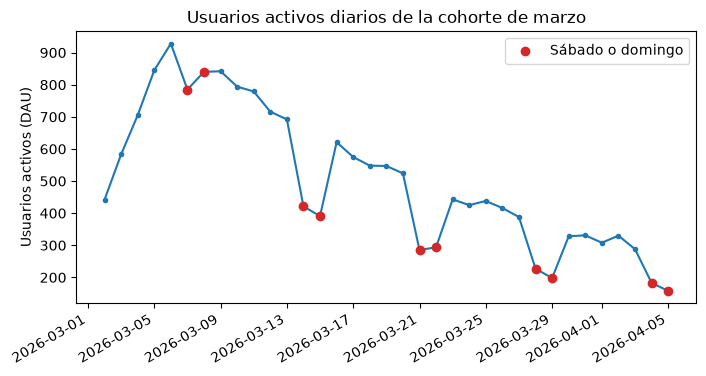

In [3]:
diario = eventos.groupby("fecha").agg(
    dau=("usuario_id", "nunique"),
    minutos=("minutos", "sum"),
)
diario["min_por_usuario"] = diario["minutos"] / diario["dau"]
diario["fin_de_semana"] = diario.index.dayofweek >= 5

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(diario.index, diario["dau"], marker="o", markersize=3)
finde = diario[diario["fin_de_semana"]]
ax.scatter(finde.index, finde["dau"], color="tab:red", zorder=3, label="Sábado o domingo")
ax.set_title("Usuarios activos diarios de la cohorte de marzo")
ax.set_ylabel("Usuarios activos (DAU)")
ax.legend()
fig.autofmt_xdate()
plt.show()

In [4]:
diario.groupby("fin_de_semana")[["dau", "min_por_usuario"]].mean().round(1)

,dau,min_por_usuario
fin_de_semana,,
False,553.4,33.9
True,378.2,33.6


In [5]:
top = (
    eventos.groupby("contenido")
    .agg(minutos=("minutos", "sum"), oyentes=("usuario_id", "nunique"))
    .sort_values("minutos", ascending=False)
    .head(5)
)
top.round(0)

,minutos,oyentes
contenido,,
Código Abierto,49909.0,793
Expedientes del Sur,46218.0,738
Casos Fríos,45361.0,721
Risas de Sobremesa,43068.0,659
Comedia sin Guion,42163.0,676


- La tabla tiene 26 448 sesiones de los 3 000 usuarios, 1 500 por grupo, entre el 2 de marzo y el 5 de abril de 2026.
- **Evolución.** El DAU sube durante la semana de altas hasta su máximo de **928 usuarios el viernes 6 de marzo** y después cae de forma sostenida: en la última semana laborable ronda los 290–330 usuarios y el último domingo baja a 158. Es la curva típica de una cohorte: cada día algunos usuarios dejan de escuchar y no entran usuarios nuevos que los sustituyan.
- **Patrón semanal.** Los sábados y domingos el DAU cae con fuerza: de 692 el viernes 13 a 421 el sábado 14, y de 524 a 285 la semana siguiente. En promedio hay 553 usuarios activos en días laborables y 378 en fin de semana, y ese promedio de fin de semana todavía incluye el primero, inflado por las altas del 7 y 8 de marzo. En cambio, los **minutos por usuario activo** apenas cambian (33.9 frente a 33.6): el fin de semana escucha menos gente, pero quien escucha lo hace igual. Encaja con un consumo ligado a la rutina de los días laborables, como los trayectos al trabajo.
- **Programas más escuchados.** "Código Abierto" encabeza la lista con unos 49 900 minutos y 793 oyentes; le siguen dos programas de crimen y dos de humor.

**Por qué el DAU no basta.** Esta es una cohorte cerrada: como no se registran usuarios nuevos después del 8 de marzo, su DAU solo puede bajar, aunque el producto mejore. En la plataforma completa ocurre lo contrario: una campaña de captación sube el DAU aunque los usuarios se vayan igual de rápido. El DAU mezcla la calidad del producto con la llegada de usuarios y el calendario. Para evaluar una mejora hay que medir la **retención por cohorte** y compararla con un **grupo de control**, que es lo que hace la Tarea 6.

### Tarea 5. Recomendación por coocurrencia

La matriz usuario × programa indica qué programas escuchó cada usuario. Al multiplicar su traspuesta por ella, la celda $(X, Y)$ suma, usuario por usuario, el producto de dos ceros o unos: cuenta los usuarios que escucharon **ambos** programas. La diagonal $(X, X)$ es el número de oyentes de $X$.

In [6]:
# 1 si el usuario escuchó el programa al menos una vez
escucho = pd.crosstab(eventos["usuario_id"], eventos["contenido"]).gt(0).astype(int)
print(escucho.shape)

coocurrencia = escucho.T @ escucho
oyentes = pd.Series(np.diag(coocurrencia), index=coocurrencia.index)
p_oyente = oyentes / len(escucho)  # P(Y): proporción de usuarios que escucharon Y

coocurrencia.loc[["Startups al Día", "Código Abierto", "Crimen sin Resolver"],
                 ["Startups al Día", "Código Abierto", "Crimen sin Resolver", "Historias de Abuela"]]

(3000, 15)


contenido,Startups al Día,Código Abierto,Crimen sin Resolver,Historias de Abuela
contenido,,,,
Startups al Día,654,371,129,124
Código Abierto,371,793,132,128
Crimen sin Resolver,129,132,693,251


In [7]:
def recomendar(programa, k=3):
    """Programas con mayor confianza P(Y|X) entre los oyentes de `programa`, con su lift."""
    confianza = (coocurrencia[programa] / oyentes[programa]).drop(programa)
    tabla = pd.DataFrame({
        "categoria": catalogo.set_index("contenido")["categoria"],
        "confianza": confianza,
        "lift": confianza / p_oyente,
    }).dropna()
    return tabla.sort_values("confianza", ascending=False).head(k).round(3)


print("Oyentes de 'Startups al Día':", oyentes["Startups al Día"])
recomendar("Startups al Día")

Oyentes de 'Startups al Día': 654


,categoria,confianza,lift
contenido,,,
Código Abierto,Negocios y tecnología,0.567,2.146
Finanzas en Corto,Negocios y tecnología,0.352,1.628
Crimen sin Resolver,Crimen,0.197,0.854


In [8]:
print("Oyentes de 'Crimen sin Resolver':", oyentes["Crimen sin Resolver"])
recomendar("Crimen sin Resolver")

Oyentes de 'Crimen sin Resolver': 693


,categoria,confianza,lift
contenido,,,
Casos Fríos,Crimen,0.395,1.645
Expedientes del Sur,Crimen,0.392,1.596
Historias de Abuela,Cultura,0.362,1.570


- **"Startups al Día".** El 56.7 % de sus 654 oyentes también escuchó "Código Abierto", con un lift de 2.15: es más del doble de lo esperable por la popularidad de "Código Abierto". "Finanzas en Corto", de la misma categoría, sigue con un lift de 1.63.
- La tercera recomendación, "Crimen sin Resolver", tiene una confianza del 19.7 % pero un **lift de 0.85**, menor que 1: los oyentes de "Startups al Día" escuchan ese programa *menos* que el usuario promedio. Aparece solo porque es un programa popular. Por eso hay que mirar el lift: la confianza sola tiende a recomendar a todo el mundo los programas más escuchados.
- **"Crimen sin Resolver".** Las dos primeras recomendaciones son de su categoría ("Casos Fríos" y "Expedientes del Sur", lift de 1.6), pero la tercera, **"Historias de Abuela", es de Cultura**: el 36.2 % de sus oyentes la escucharon, con un lift de 1.57. Es una asociación entre categorías que una regla del tipo "recomienda programas de la misma categoría" nunca encontraría.

En la práctica, conviene recomendar solo pares con lift claramente mayor que 1 y con suficientes oyentes en común. La coocurrencia es un buen punto de partida para una startup: es fácil de explicar y de calcular, aunque no personaliza según la intensidad de escucha ni sirve para programas nuevos sin oyentes.

### Tarea 6. Prueba A/B de la cola automática

**Hipótesis.** Sean $p_A$ y $p_B$ las proporciones de usuarios retenidos en la semana 4 en cada grupo:

- $H_0: p_A = p_B$ (la cola automática no cambia la retención).
- $H_1: p_A \neq p_B$ (prueba bilateral; no se presupone la dirección del efecto).

Con muestras grandes, el estadístico $z = \dfrac{\hat{p}_B - \hat{p}_A}{\sqrt{\hat{p}(1-\hat{p})\left(\frac{1}{n_A} + \frac{1}{n_B}\right)}}$, donde $\hat{p}$ es la proporción conjunta, sigue aproximadamente una normal estándar bajo $H_0$.

El primer paso es fijar la fecha de alta de cada usuario y contar los días desde el alta. El denominador de la retención debe ser **todos** los usuarios de cada grupo, no solo los que siguieron activos.

In [9]:
from statsmodels.stats.proportion import confint_proportions_2indep, proportions_ztest

alta = eventos.groupby("usuario_id")["fecha"].min()
eventos["dias_desde_alta"] = (eventos["fecha"] - eventos["usuario_id"].map(alta)).dt.days

usuarios = eventos.groupby("usuario_id")["grupo"].first().to_frame()
activos_sem4 = eventos.loc[eventos["dias_desde_alta"].between(21, 27), "usuario_id"].unique()
usuarios["retenido"] = usuarios.index.isin(activos_sem4)

retencion = usuarios.groupby("grupo")["retenido"].agg(usuarios="size", retenidos="sum", proporcion="mean")
retencion.round(4)

,usuarios,retenidos,proporcion
grupo,,,
A,1500,718,0.4787
B,1500,782,0.5213


In [10]:
x_a, n_a = retencion.loc["A", "retenidos"], retencion.loc["A", "usuarios"]
x_b, n_b = retencion.loc["B", "retenidos"], retencion.loc["B", "usuarios"]

z, p_valor = proportions_ztest(count=[x_b, x_a], nobs=[n_b, n_a])
print(f"z = {z:.3f}, p-valor = {p_valor:.4f}")

# Tamaño del efecto
p_a, p_b = x_a / n_a, x_b / n_b
ic_inf, ic_sup = confint_proportions_2indep(x_b, n_b, x_a, n_a, compare="diff")
print(f"Retención A = {p_a:.1%}, B = {p_b:.1%}")
print(f"Diferencia B - A = {100 * (p_b - p_a):.1f} puntos porcentuales "
      f"(IC 95 %: {100 * ic_inf:.1f} a {100 * ic_sup:.1f})")
print(f"Aumento relativo = {(p_b - p_a) / p_a:.1%}")

z = 2.337, p-valor = 0.0194
Retención A = 47.9%, B = 52.1%
Diferencia B - A = 4.3 puntos porcentuales (IC 95 %: 0.7 a 7.8)
Aumento relativo = 8.9%


Como métrica de control se comparan los minutos por usuario en sus primeros 28 días (días 0 a 27), una ventana igual para todos.

In [11]:
primeros_28 = eventos[eventos["dias_desde_alta"] <= 27]
minutos_usuario = primeros_28.groupby("usuario_id")["minutos"].sum()
usuarios["minutos_28d"] = minutos_usuario.reindex(usuarios.index, fill_value=0)
usuarios.groupby("grupo")["minutos_28d"].agg(["mean", "median"]).round(1)

,mean,median
grupo,,
A,184.0,158.6
B,193.4,174.6


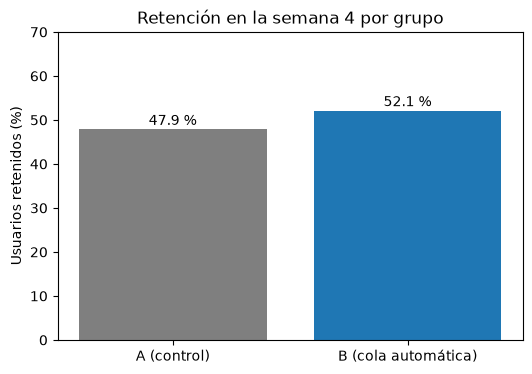

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(retencion.index, retencion["proporcion"] * 100, color=["tab:gray", "tab:blue"])
for i, valor in enumerate(retencion["proporcion"] * 100):
    ax.text(i, valor + 1, f"{valor:.1f} %", ha="center")
ax.set_title("Retención en la semana 4 por grupo")
ax.set_xticks([0, 1], ["A (control)", "B (cola automática)"])
ax.set_ylabel("Usuarios retenidos (%)")
ax.set_ylim(0, 70)
plt.show()

**Resultado de la prueba.** El 47.9 % de los usuarios del grupo A (718 de 1 500) siguió escuchando en la semana 4, frente al 52.1 % del grupo B (782 de 1 500). La prueba z da $z = 2.34$ y un **p-valor de 0.019**, menor que $\alpha = 0.05$, así que se rechaza $H_0$.

**Cómo leer el p-valor.** Si la cola automática no tuviera ningún efecto, la probabilidad de observar una diferencia de al menos este tamaño (en cualquier dirección) por el azar de la asignación sería de alrededor del 1.9 %. No es la probabilidad de que $H_0$ sea cierta ni dice cuán grande es el efecto.

**Tamaño del efecto.** La diferencia es de **4.3 puntos porcentuales**, un aumento relativo del 8.9 %: unos 43 usuarios retenidos más por cada 1 000 altas. El intervalo de confianza del 95 % va de **0.7 a 7.8 puntos**: el efecto es positivo, pero podría ser desde casi insignificante hasta bastante importante. El experimento descarta que la función no haga nada, pero no mide su efecto con precisión.

**Métrica de control.** Los usuarios del grupo B escucharon en sus primeros 28 días una media de 193.4 minutos y una mediana de 174.6, frente a 184.0 y 158.6 en el grupo A. La función no reduce la escucha; si acaso, la aumenta. Es una comparación descriptiva: no se le aplicó una prueba formal.

**Recomendación.** Lanzar la cola automática a todos los usuarios, porque el efecto es positivo, la métrica de control no empeora y la función tiene un costo bajo. Conviene mantener un pequeño grupo de control durante unas semanas más para afinar la estimación.

**Límites.**

- Solo se observaron 4 semanas: el efecto podría deberse en parte a la novedad y desvanecerse, o mantenerse a más largo plazo; habría que seguir la retención a 8 y 12 semanas.
- La retención cuenta cualquier sesión. Si la cola reproduce episodios que el usuario no escucha de verdad, la métrica se inflaría; convendría añadir como control la proporción de episodios abandonados en los primeros minutos.
- El resultado vale para usuarios nuevos de marzo; no se sabe si se repite con usuarios antiguos o en otra temporada.
- La retención en la semana 4 debe haberse fijado como métrica principal **antes** del experimento: si se prueban muchas métricas y se reporta la que sale significativa, el p-valor pierde su significado.

## Conclusiones

- Para una startup de pódcast, las primeras aplicaciones de la ciencia de datos deberían ser la **medición con experimentos** y la **recomendación**: tienen alto impacto en la retención y funcionan con los datos de escucha que ya existen.
- Un equipo de cinco personas (líder, ingeniería de datos, analista de producto y dos perfiles de ciencia de datos), contratado en ese orden, cubre esas aplicaciones sin sobredimensionarse.
- El DAU de una cohorte siempre baja y depende del día de la semana (553 usuarios en días laborables frente a 378 en fines de semana), así que el éxito se mide con la **retención por cohorte** y con grupos de control.
- La coocurrencia con lift encuentra asociaciones útiles, incluso entre categorías ("Crimen sin Resolver" → "Historias de Abuela"), y descarta recomendaciones que solo reflejan popularidad.
- La cola automática aumenta la retención en la semana 4 en 4.3 puntos (p = 0.019; IC 95 % de 0.7 a 7.8) sin reducir los minutos escuchados: es razonable lanzarla y seguir midiendo su efecto a más largo plazo.